Credit Card Fraud Detection with Concept Drift 2026

This dataset contains 120,000 credit card transactions spanning January to June 2026, with 73 carefully engineered features covering transaction characteristics, customer and merchant profiles, velocity signals, authentication behaviour, dispute outcomes, and temporal drift metadata.

It is designed specifically for research on multiclass fraud classification under concept drift - one of the most challenging and underexplored problems in financial machine learning. No other publicly available fraud dataset combines real-world-style fraud type taxonomy, gradual inter-class drift mechanics, delayed label availability, and post-transaction dispute outcomes in a single file.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression

In [2]:
credit_fraud_data = pd.read_csv('/Users/maheshg/Dropbox/Sample Datasets Kaggle/credit_card_fraud_drift_2026.csv')

In [3]:
credit_fraud_data.size

8760000

In [4]:
credit_fraud_data.ndim

2

In [5]:
credit_fraud_data.head()

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,TX4042000000000,CU00022008,CA000000001,ME000381,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,TX4042000000001,CU00000598,CA000000002,ME000764,2026-01-01 00:00:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,TX4042000000002,CU00018179,CA000000003,ME001251,2026-01-01 00:03:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,TX4042000000003,CU00023636,CA000000004,ME002627,2026-01-01 00:04:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,TX4042000000004,CU00028521,CA000000005,ME004940,2026-01-01 00:05:00,1,1,1,0,0.0,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period


In [6]:
credit_fraud_data.columns

Index(['transaction_id', 'customer_id', 'card_id', 'merchant_id',
       'transaction_datetime', 'month', 'week_of_year', 'drift_phase',
       'days_into_phase', 'drift_magnitude', 'transaction_amount',
       'merchant_category', 'merchant_country', 'transaction_hour',
       'transaction_day_of_week', 'card_present', 'customer_age',
       'customer_gender', 'customer_country', 'account_age_days',
       'credit_limit', 'credit_score', 'num_cards_held',
       'transactions_last_1h', 'transactions_last_24h', 'transactions_last_7d',
       'amount_last_1h', 'amount_last_24h', 'days_since_last_transaction',
       'distance_from_home_km', 'distance_from_last_tx_km',
       'international_transaction', 'high_risk_country', 'amount_vs_avg_ratio',
       'used_chip', 'used_pin', 'transaction_channel', 'device_type',
       'browser', 'is_weekend', 'avg_transaction_amount_30d',
       'std_transaction_amount_30d', 'num_declined_last_30d',
       'num_chargebacks_ever', 'email_domain', 'fa

In [7]:
credit_fraud_data.dtypes

transaction_id                         object
customer_id                            object
card_id                                object
merchant_id                            object
transaction_datetime                   object
                                       ...   
dispute_adjudicated_friendly_fraud      int64
dispute_delay_days                    float64
dispute_event_datetime                 object
adjudication_datetime                  object
dispute_regime                         object
Length: 73, dtype: object

In [8]:
credit_fraud_data.describe()

,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,...,label_available,label_delay_days,pseudo_label,is_fraud,fraud_amount_lost,post_transaction_outcome,transaction_time_eligible,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days
count,120000.000000,120000.00000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,...,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,120000.000000,2693.000000
mean,3.509708,13.86245,2.342708,24.584083,0.316672,46.327703,11.466783,0.488842,41.858283,846.398217,...,0.900583,11.804117,-0.891217,0.094892,4.295675,0.004392,0.984225,0.022442,0.008500,30.857779
std,1.709794,7.47403,1.099130,16.560963,0.326347,36.972352,6.912716,0.499878,13.442005,916.128151,...,0.299222,13.943989,0.340123,0.293066,17.700369,0.066124,0.124604,0.148116,0.091803,17.349079
min,1.000000,1.00000,1.000000,0.000000,0.000000,1.500000,0.000000,0.000000,18.000000,15.000000,...,0.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,7.00000,1.000000,11.000000,0.000000,22.720000,5.000000,0.000000,32.000000,311.000000,...,1.000000,0.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,16.000000
50%,4.000000,14.00000,3.000000,22.000000,0.480000,36.290000,11.000000,0.000000,42.000000,537.000000,...,1.000000,7.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,31.000000
75%,5.000000,20.00000,3.000000,37.000000,0.620000,57.900000,17.000000,1.000000,51.000000,1014.000000,...,1.000000,21.000000,-1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,46.000000
max,6.000000,27.00000,4.000000,60.000000,0.780000,1030.590000,23.000000,1.000000,90.000000,24603.000000,...,1.000000,45.000000,1.000000,1.000000,504.800000,1.000000,1.000000,1.000000,1.000000,60.000000


In [9]:
print(credit_fraud_data.isna().sum())

transaction_id                             0
customer_id                                0
card_id                                    0
merchant_id                                0
transaction_datetime                       0
                                       ...  
dispute_adjudicated_friendly_fraud         0
dispute_delay_days                    117307
dispute_event_datetime                117307
adjudication_datetime                 117307
dispute_regime                             0
Length: 73, dtype: int64


Understanding the target 

In [12]:
credit_fraud_data['is_fraud'].value_counts()

is_fraud
0    108613
1     11387
Name: count, dtype: int64

In [13]:
credit_fraud_data['is_fraud'].value_counts(normalize=True)

is_fraud
0    0.905108
1    0.094892
Name: proportion, dtype: float64

Removing the data leakage - this is the most important step where fraud teams only know information available at this time. Hence removing some features from the dataset 
    fraud_type
    fraud_amount_lost

    post_transaction_outcome

    dispute_filed

    dispute_delay_days

    dispute_event_datetime

    adjudication_datetime

    dispute_adjudicated_friendly_fraud

    label_available

    label_delay_days

    pseudo_label



Removing the Identifier Columns

    transaction_id                         object
    customer_id                            object
    card_id                                object
    merchant_id                            object
    transaction_datetime 

In [18]:
credit_fraud_data.drop(columns = [
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id',
    'transaction_datetime'
])

,month,week_of_year,drift_phase,days_into_phase,drift_magnitude,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,...,drift_phase_name,post_transaction_outcome,transaction_time_eligible,transaction_time_target,dispute_filed,dispute_adjudicated_friendly_fraud,dispute_delay_days,dispute_event_datetime,adjudication_datetime,dispute_regime
0,1,1,1,0,0.00,16.34,subscription,SG,0,Thursday,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
1,1,1,1,0,0.00,27.88,grocery,IE,0,Thursday,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
2,1,1,1,0,0.00,24.71,grocery,IN,0,Thursday,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
3,1,1,1,0,0.00,62.07,electronics,US,0,Thursday,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
4,1,1,1,0,0.00,46.23,health,US,0,Thursday,...,stable_training,0,1,Legitimate,0,0,NaN,NaN,NaN,early_period
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119995,6,27,4,29,0.48,38.77,fuel,CA,23,Tuesday,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119996,6,27,4,29,0.48,47.61,subscription,CA,23,Tuesday,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119997,6,27,4,29,0.48,49.38,grocery,US,23,Tuesday,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period
119998,6,27,4,29,0.48,37.66,health,US,23,Tuesday,...,partial_stabilization,0,1,Legitimate,0,0,NaN,NaN,NaN,later_period


In [20]:
credit_fraud_data.isnull().sum()

transaction_id                             0
customer_id                                0
card_id                                    0
merchant_id                                0
transaction_datetime                       0
                                       ...  
dispute_adjudicated_friendly_fraud         0
dispute_delay_days                    117307
dispute_event_datetime                117307
adjudication_datetime                 117307
dispute_regime                             0
Length: 73, dtype: int64

Numerical

In [21]:
from sklearn.impute import SimpleImputer

In [22]:
num_imputer = SimpleImputer(strategy='median')

Categorical

In [23]:
cat_imputer = SimpleImputer(strategy='most_frequent')

Perform the Exploratory Data Analysis 

<Axes: xlabel='is_fraud', ylabel='count'>

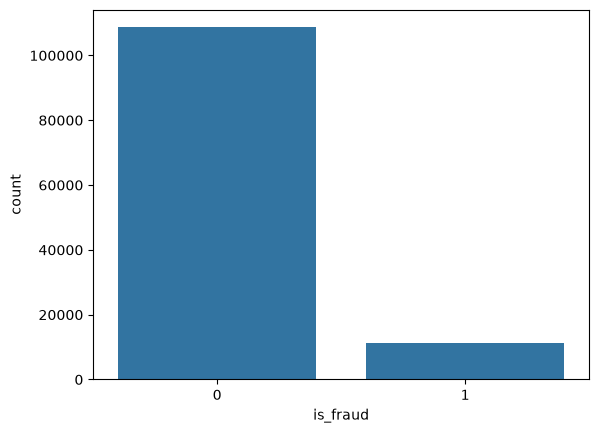

In [24]:
sns.countplot(
    x = 'is_fraud',
    data = credit_fraud_data
)

<Axes: xlabel='is_fraud', ylabel='transaction_amount'>

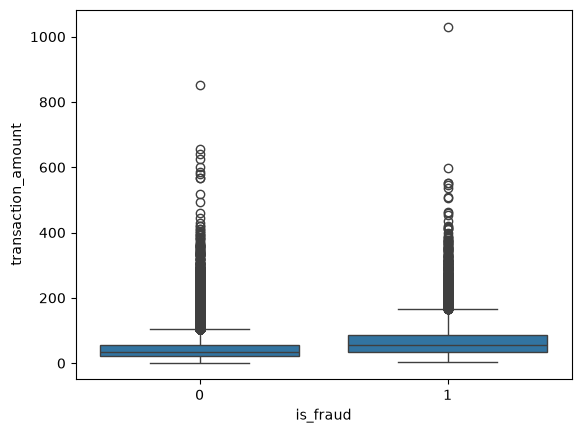

In [25]:
sns.boxplot(
    x = 'is_fraud',
    y = 'transaction_amount',
    data = credit_fraud_data)

In [28]:
pd.crosstab(
    credit_fraud_data.transaction_channel,
    credit_fraud_data.is_fraud
)

is_fraud,0,1
transaction_channel,,
ATM,7634,596
POS,46932,3294
ecommerce,31333,4042
mobile_app,17254,2688
recurring,5460,767


Note - In the above table, online transaction using ecommerce website has more fraud happening 

In [29]:
pd.crosstab(
    credit_fraud_data.high_risk_country,
    credit_fraud_data.is_fraud
)

is_fraud,0,1
high_risk_country,,
0,103485,8708
1,5128,2679


<Axes: xlabel='is_fraud', ylabel='failed_auth_attempts_24h'>

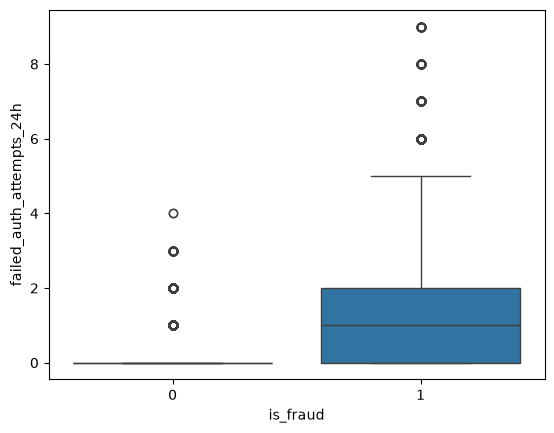

In [32]:
sns.boxplot(
    x = 'is_fraud',
    y = 'failed_auth_attempts_24h',
    data = credit_fraud_data
)

Splitting the dataset into two chunks - train and test using time based spit important

Training 

In [33]:
train = credit_fraud_data[credit_fraud_data.month <= 8]

Validation

In [34]:
valid = credit_fraud_data[credit_fraud_data.month == 9]

Testing

In [35]:
test = credit_fraud_data[credit_fraud_data.month == 10]

Building Preprocessing Pipeline

In [36]:
from sklearn.preprocessing import OneHotEncoder


OneHotEncoder(
    handle_unknown='ignore'
)

,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'ignore'
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",True
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'numpy.float64'>
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequen

In [38]:
from sklearn.preprocessing import StandardScaler


StandardScaler()

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Building Logistic Regression 

In [39]:
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

Train Model : 

In [42]:
leakage_cols = [
    'fraud_type',
    'fraud_amount_lost',
    'post_transaction_outcome',
    'dispute_filed',
    'dispute_delay_days',
    'dispute_event_datetime',
    'adjudication_datetime',
    'dispute_adjudicated_friendly_fraud',
    'pseudo_label'
]

In [43]:
id_cols = [
    'transaction_id',
    'customer_id',
    'card_id',
    'merchant_id'
]

In [44]:
target = 'is_fraud'

In [45]:
features_to_drop = leakage_cols + id_cols + [target]
X_train = train.drop(columns=features_to_drop)
y_train = train[target]
X_valid = valid.drop(columns=features_to_drop)
y_valid = valid[target]
X_test = test.drop(columns=features_to_drop)
y_test = test[target]

In [ ]:
categorical_cols = X_train.select_dtypes(
    include=['object']
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical:", len(categorical_cols))
print("Numerical:", len(numerical_cols))


In [48]:
from sklearn.pipeline import Pipeline


numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]
)

In [49]:
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

In [51]:
from sklearn.compose import ColumnTransformer


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

In [52]:
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            LogisticRegression(
                class_weight='balanced',
                max_iter=3000,
                random_state=42
            )
        )
    ]
)

In [60]:
model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](59,)","['transaction_datetime','month','week_of_year',..., 'transaction_time_eligible','transaction_time_target','dispute_regime']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,59
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``